In [14]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d

from numcosmo_ep2 import lpt, growth

In [15]:
L = 500.0          # Mpc/h
N = 256
seed = 1234
a_ref = 1.0

dx = L / N
V = L**3

kf = 2.0 * np.pi / L
kNy = np.pi * N / L

print(f"N              = {N}")
print(f"L              = {L:.1f} Mpc/h")
print(f"dx             = {dx:.4f} Mpc/h")
print(f"k_fundamental  = {kf:.5f} h/Mpc")
print(f"k_Nyquist      = {kNy:.5f} h/Mpc")
print(f"reference a    = {a_ref}")
print(f"seed           = {seed}")

N              = 256
L              = 500.0 Mpc/h
dx             = 1.9531 Mpc/h
k_fundamental  = 0.01257 h/Mpc
k_Nyquist      = 1.60850 h/Mpc
reference a    = 1.0
seed           = 1234


In [16]:
pk_data = np.loadtxt("../outputs/class/base_pk.dat")

k_class = pk_data[:, 0]
P_class = pk_data[:, 1]

logP_interp = interp1d(np.log(k_class), np.log(P_class), kind="linear", bounds_error=True)

def classPower(k):
    k = np.asarray(k)

    P = np.zeros_like(k, dtype=float)
    mask = k > 0.0

    P[mask] = np.exp(logP_interp(np.log(k[mask])))

    return P

_, _, _, _, _, _, kmag = lpt.fourierGrid(N, L)

print(f"CLASS k range = [{k_class.min():.4g}, {k_class.max():.4g}] h/Mpc")
print(f"Grid |k| max  = {kmag.max():.4g} h/Mpc")

CLASS k range = [1.048e-05, 6.694] h/Mpc
Grid |k| max  = 2.786 h/Mpc


# Gaussian field (3a)

In [17]:
delta_k, delta_x = lpt.gaussianField(N, L, classPower, seed=seed)
print("delta_k shape =", delta_k.shape)
print("delta_x shape =", delta_x.shape)

delta_k shape = (256, 256, 129)
delta_x shape = (256, 256, 256)


In [18]:
delta_k_roundtrip = dx**3 * np.fft.rfftn(delta_x)
roundtrip_residual = np.linalg.norm(delta_k_roundtrip - delta_k) / np.linalg.norm(delta_k)

print(f"<delta(x)>              = {delta_x.mean(): .3e}")
print(f"delta_k[0,0,0]          = {delta_k[0,0,0]: .3e}")
print(f"std(delta)              = {delta_x.std(): .6e}")
print(f"min/max delta           = {delta_x.min(): .4e}, {delta_x.max(): .4e}")
print(f"FFT round-trip residual = {roundtrip_residual: .3e}")

<delta(x)>              =  2.412e-18
delta_k[0,0,0]          =  0.000e+00+0.000e+00j
std(delta)              =  2.536395e+00
min/max delta           = -1.2692e+01,  1.4336e+01
FFT round-trip residual =  4.593e-16


The realization sucessfully satisfies $\langle\delta\rangle\simeq0$, has the zero mode $\delta_\mathbf{0}\simeq 0$ and a negligible error for a full circle of FFT/IFFT.  

In [19]:
delta_full = dx**3 * np.fft.fftn(delta_x)

idx = (-np.arange(N)) % N
delta_minus = delta_full[np.ix_(idx, idx, idx)]
hermitian_residual = np.linalg.norm(delta_minus - np.conj(delta_full)) / np.linalg.norm(delta_full)

print(f"Hermitian residual      = {hermitian_residual:.3e}")

delta_complex = np.fft.ifftn(delta_full / dx**3)
imag_residual = np.max(np.abs(delta_complex.imag))

print(f"max imaginary residual  = {imag_residual:.3e}")

Hermitian residual      = 4.416e-16
max imaginary residual  = 4.754e-15


Since our implementation uses the native rfft from numpy, the Hermitian symmetry is imposed by construction providing the half-spectrum. However, we can construct the full spectrum through fft of the real space delta, as to show that the Hermitian property $\delta_{-\mathbf{k}}=\delta_\mathbf{k}^*$ with a negligible residual.

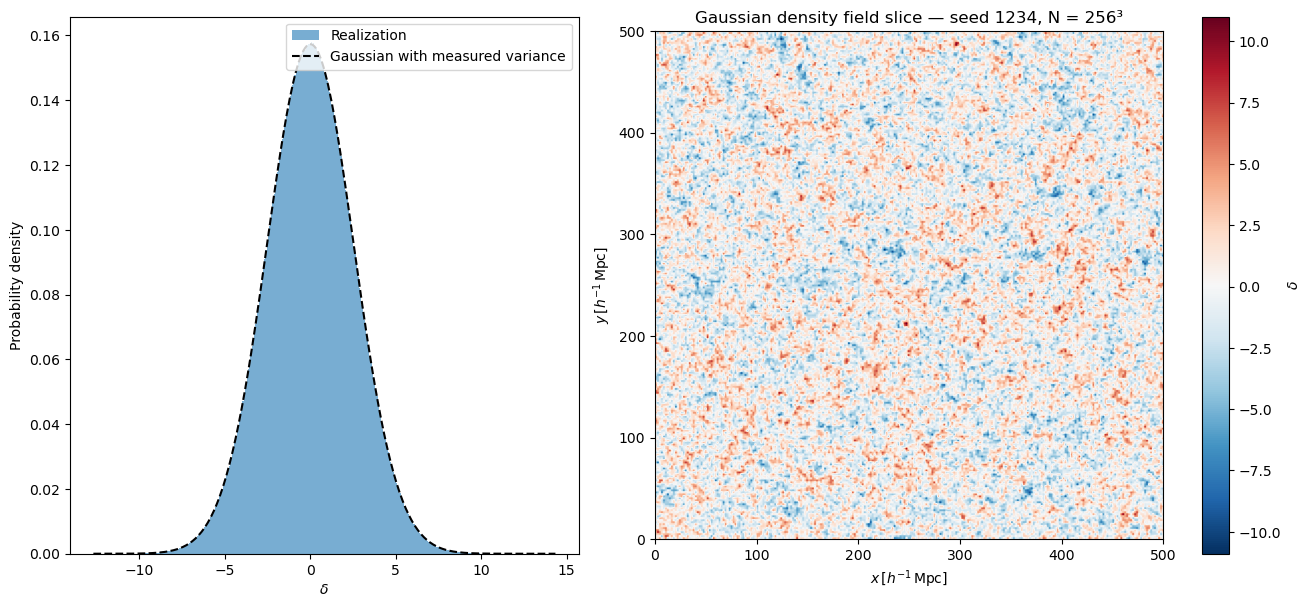

In [20]:
iz = N // 2
sigma = delta_x.std()
xg = np.linspace(delta_x.min(), delta_x.max(), 300)
gaussian_pdf = np.exp(-0.5 * (xg / sigma)**2) / (np.sqrt(2.0 * np.pi) * sigma)

fig, ax = plt.subplots(ncols=2, figsize=(13, 6), layout="constrained")

ax[0].hist(delta_x.ravel(), bins=400, density=True, alpha=0.6, label=f"Realization")
ax[0].plot(xg, gaussian_pdf, c="k", ls="--", label="Gaussian with measured variance")

ax[0].set_xlabel(r"$\delta$")
ax[0].set_ylabel("Probability density")
ax[0].legend()

im = ax[1].imshow(delta_x[:, :, iz].T, origin="lower", extent=(0, L, 0, L), 
                  aspect="equal", cmap="RdBu_r")

ax[1].set_xlabel(r"$x\,[h^{-1}\,\mathrm{Mpc}]$")
ax[1].set_ylabel(r"$y\,[h^{-1}\,\mathrm{Mpc}]$")
ax[1].set_title(rf"Gaussian density field slice — seed {seed}, N = {N}³")

fig.colorbar(im, ax=ax[1], label=r"$\delta$")
plt.savefig("../outputs/figures/03_gaussian_field.png", dpi=200)
plt.show()

Here we show the full real gaussian field provided by the implementation, and check that the distribution of $\delta$ is indeed a gaussian with zero mean. Their values, however, are not independent, since there are spatial correlations in the $\delta$ generated.

One can see, also, that subtle visual artifacts that align with the preferential grid directions. The following figure provides an explanation for such phenomena.

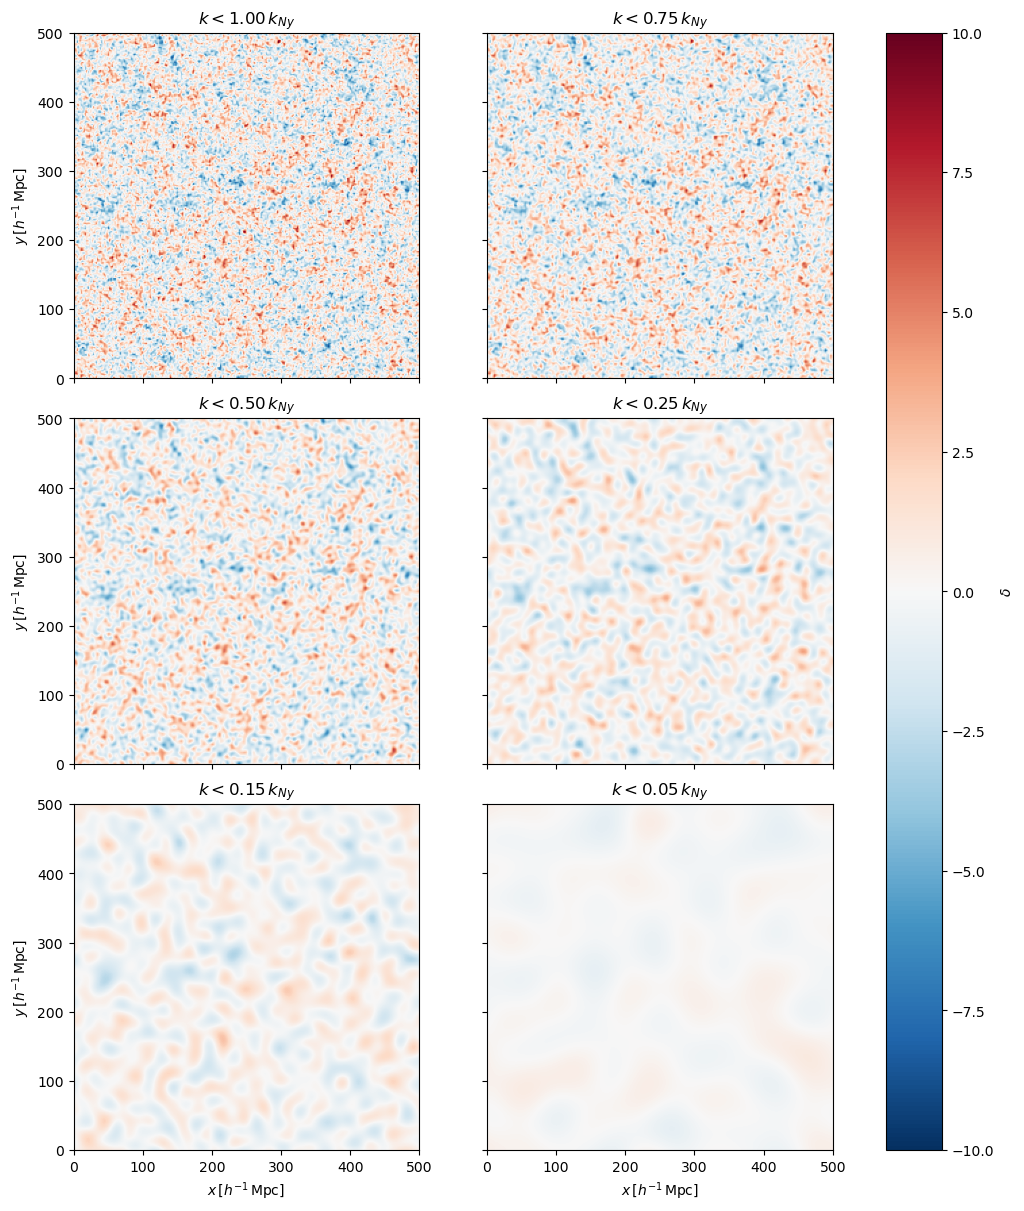

In [31]:
kNy = np.pi * N / L
fig, ax = plt.subplots(nrows=3, ncols=2, figsize=(10, 12), layout="constrained", sharex=True, sharey=True)

for i, frac in enumerate([1.0, 0.75, 0.5, 0.25, 0.15, 0.05]):
    mask = kmag <= frac * kNy
    dk_filtered = delta_k * mask
    dx_filtered = np.fft.irfftn(dk_filtered / dx**3, s=(N, N, N), axes=(0, 1, 2))

    im = ax[i//2][i%2].imshow(dx_filtered[:, :, N//2].T, origin="lower", extent=(0, L, 0, L), 
                         aspect="equal", vmin=-10, vmax=10, cmap="RdBu_r")
    ax[i//2][i%2].set_title(rf"$k < {frac:.2f}\,k_{{Ny}}$")

ax[2][0].set_xlabel(r"$x\,[h^{-1}\,\mathrm{Mpc}]$")
ax[2][1].set_xlabel(r"$x\,[h^{-1}\,\mathrm{Mpc}]$")
ax[0][0].set_ylabel(r"$y\,[h^{-1}\,\mathrm{Mpc}]$")
ax[1][0].set_ylabel(r"$y\,[h^{-1}\,\mathrm{Mpc}]$")
ax[2][0].set_ylabel(r"$y\,[h^{-1}\,\mathrm{Mpc}]$")

fig.colorbar(im, ax=ax, fraction=.1, label=r"$\delta$")

plt.savefig("../outputs/figures/03_gaussian_field_resolution.png", dpi=200)
plt.show()

In this Figure, before extracting each real $\delta$ density with IFFT, we first apply a low-pass over $k$ values under a fraction of the Nyquist frequency $k_\mathrm{Ny}$. We can qualitatively see that the visual artifacts disappear if we filter out the frequencies close to $k_\mathrm{Ny}$, so we can explain this effect as a sampling limitation over frequencies close to the limits of spatial resolution sampled.

At the largest scales (low frequencies $k$), the densities are homogeneous, such that the $\delta$ sobredensities tend to zero.

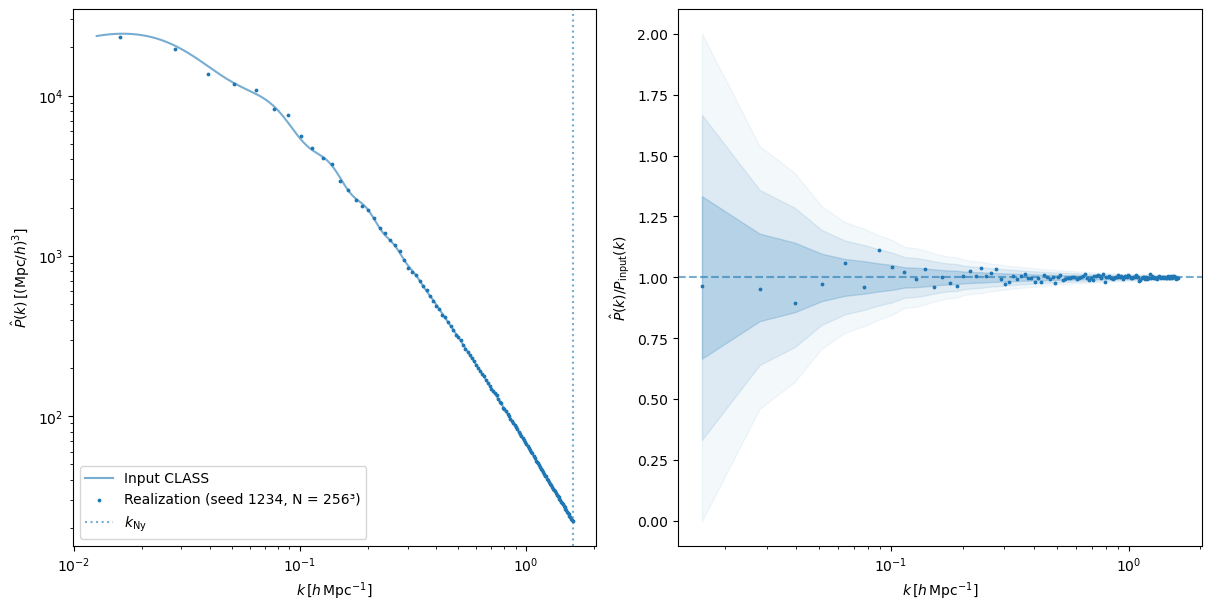

k=  0.0160  P/Pinput=  0.967  Nmodes=    18
k=  0.0280  P/Pinput=  0.951  Nmodes=    62
k=  0.0394  P/Pinput=  0.895  Nmodes=    98
k=  0.0510  P/Pinput=  0.971  Nmodes=   210
k=  0.0641  P/Pinput=  1.058  Nmodes=   350
k=  0.0769  P/Pinput=  0.960  Nmodes=   450
k=  0.0889  P/Pinput=  1.112  Nmodes=   602
k=  0.1008  P/Pinput=  1.043  Nmodes=   762
k=  0.1138  P/Pinput=  1.023  Nmodes=  1142
k=  0.1268  P/Pinput=  0.992  Nmodes=  1250


In [34]:
Pk_grid = classPower(kmag)
bins = np.arange(0.5 * kf, kNy + 1.5 * kf, kf)

kbin, Pmeasured, Nmodes = lpt.shellAveragePower(delta_k, kmag, L, N,bins)
_, Pinput = lpt.shellAverageInputPower(kmag, Pk_grid, N, bins)
mask_plot = (k_class >= kf) & (k_class <= kNy)

ratio = Pmeasured / Pinput
sigma_ratio = np.sqrt(2.0 / Nmodes)

fig, ax = plt.subplots(ncols=2, figsize=(12, 6), layout="constrained")

ax[0].loglog(k_class[mask_plot], P_class[mask_plot], alpha=0.6, label="Input CLASS")
ax[0].scatter(kbin, Pmeasured, s=3, label=f"Realization (seed {seed}, N = {N}³)")
ax[0].axvline(kNy, ls=":", alpha=0.6, label=r"$k_{\rm Ny}$")

ax[0].set_xlabel(r"$k\,[h\,\mathrm{Mpc}^{-1}]$")
ax[0].set_ylabel(r"$\hat P(k)\,[(\mathrm{Mpc}/h)^3]$")
ax[0].legend()

ax[1].axhline(1.0, ls="--", alpha=0.6)
ax[1].scatter(kbin, ratio, s=3)
ax[1].fill_between(kbin, 1.0 - sigma_ratio, 1.0 + sigma_ratio, alpha=0.2, color="C0", label=r"$1\sigma:\ \sqrt{2/N_{\rm modes}}$")
ax[1].fill_between(kbin, 1.0 - 2*sigma_ratio, 1.0 + 2*sigma_ratio, alpha=0.1, color="C0", label=r"$1\sigma:\ \sqrt{2/N_{\rm modes}}$")
ax[1].fill_between(kbin, 1.0 - 3*sigma_ratio, 1.0 + 3*sigma_ratio, alpha=0.05, color="C0", label=r"$1\sigma:\ \sqrt{2/N_{\rm modes}}$")

ax[1].set_xscale("log")
ax[1].set_xlabel(r"$k\,[h\,\mathrm{Mpc}^{-1}]$")
ax[1].set_ylabel(r"$\hat P(k)/P_{\rm input}(k)$")

plt.savefig("../outputs/figures/03_power_realization.png", dpi=200)
plt.show()

for k, p, pin, n in zip(kbin[:10], Pmeasured[:10], Pinput[:10], Nmodes[:10]):
    print(f"k={k:8.4f}  P/Pinput={p/pin:7.3f}  Nmodes={n:6.0f}")

Here we compare this seeded realization with the input power spectra from CLASS (at the reference $z=0$ redshift). We show that the gaussian field spectra agrees within 2 sigma with the expected input, without systematic errors. Each colored interval in the right panel shows the significance interval ($1\sigma,2\sigma,3\sigma$) to compare CLASS and realization power spectra.

# ZA positions and velocities (3b)

In [4]:
a_i = 0.02
z_i = 1.0 / a_i - 1.0

omega_b = 0.0224
omega_cdm = 0.120
omega_m = omega_b + omega_cdm
omega_lambda = 1 - omega_m
h = 0.674

G_i, D_i, f_i = growth.linearGrowth(a_i, omega_m, omega_lambda)

print(f"a_i       = {a_i:.5f}")
print(f"z_i       = {z_i:.1f}")
print(f"D_1(a_i)  = {D_i:.8f}")
print(f"f_1(a_i)  = {f_i:.8f}")

a_i       = 0.02000
z_i       = 49.0
D_1(a_i)  = 0.03083000
f_1(a_i)  = 0.99997372


In [36]:
E2_i, _, _ = growth.cosmExpansion(a_i,omega_m, omega_lambda)
E_i = np.sqrt(E2_i)

H_i = 100.0 * h * E_i             # km/s/Mpc
Hconf_i = a_i * H_i / h           # km/s/(Mpc/h)

print(f"E(a_i)        = {E_i:.6f}")
print(f"H(a_i)        = {H_i:.3f} km/s/Mpc")
print(f"Hconf_box     = {Hconf_i:.3f} km/s/(Mpc/h)")
print(f"Hconf*f       = {Hconf_i*f_i:.3f} km/s/(Mpc/h)")

E(a_i)        = 133.419855
H(a_i)        = 8992.498 km/s/Mpc
Hconf_box     = 266.840 km/s/(Mpc/h)
Hconf*f       = 266.833 km/s/(Mpc/h)


In [37]:
kxy, kz1d, kx, ky, kz, k2, kmag = lpt.fourierGrid(N, L)

psi_k, delta_used = lpt.zaDisplacementFourier(delta_k, kx, ky, kz, k2, D_i)
psi_x = lpt.displacementToReal(psi_k, N, L)

print("psi_k shape =", psi_k.shape)
print("psi_x shape =", psi_x.shape)

psi_k shape = (3, 256, 256, 129)
psi_x shape = (3, 256, 256, 256)


In [42]:
psi_mag = np.sqrt(np.sum(psi_x**2, axis=0))

lp = L / N

psi_rms = np.sqrt(np.mean(psi_mag**2))
psi_x_rms = np.sqrt(np.mean(psi_x[0]**2))
psi_y_rms = np.sqrt(np.mean(psi_x[1]**2))
psi_z_rms = np.sqrt(np.mean(psi_x[2]**2))
psi_max = np.max(psi_mag)

print(f"<Psi_x> = {psi_x[0].mean(): .3e} Mpc/h")
print(f"<Psi_y> = {psi_x[1].mean(): .3e} Mpc/h")
print(f"<Psi_z> = {psi_x[2].mean(): .3e} Mpc/h")
print(f"RMS Psi_x/lp * sqrt(3) = {psi_x_rms/lp*np.sqrt(3):.5f}")
print(f"RMS Psi_y/lp * sqrt(3) = {psi_y_rms/lp*np.sqrt(3):.5f}")
print(f"RMS Psi_z/lp * sqrt(3) = {psi_z_rms/lp*np.sqrt(3):.5f}")

print()
print(f"RMS |Psi|        = {psi_rms:.5f} Mpc/h")
print(f"max |Psi|        = {psi_max:.5f} Mpc/h")
print(f"particle spacing = {lp:.5f} Mpc/h")
print(f"RMS |Psi|/lp     = {psi_rms/lp:.5f}")
print(f"max |Psi|/lp     = {psi_max/lp:.5f}")

print()
Cpsi = np.einsum("ixyz,jxyz->ij", psi_x, psi_x) / N**3
print("C_ij =\n", Cpsi)

Ciso = np.trace(Cpsi) / 3.0
print("diagonal / isotropic expectation =", np.diag(Cpsi) / Ciso)

<Psi_x> =  5.164e-17 Mpc/h
<Psi_y> = -1.999e-19 Mpc/h
<Psi_z> = -2.917e-21 Mpc/h
RMS Psi_x/lp * sqrt(3) = 0.15916
RMS Psi_y/lp * sqrt(3) = 0.14778
RMS Psi_z/lp * sqrt(3) = 0.15723

RMS |Psi|        = 0.30235 Mpc/h
max |Psi|        = 0.99767 Mpc/h
particle spacing = 1.95312 Mpc/h
RMS |Psi|/lp     = 0.15480
max |Psi|/lp     = 0.51081

C_ij =
 [[0.03221203 0.00087232 0.00025199]
 [0.00087232 0.02776973 0.00360239]
 [0.00025199 0.00360239 0.03143389]]
diagonal / isotropic expectation = [1.05710662 0.91132312 1.03157026]


Here we diagnose the values $\sigma_\Psi/l_p=0.15480$ (with $\sigma_\Psi\equiv \sqrt{\langle\lvert\Psi\rvert^2\rangle}$) and $\max\lvert\Psi\rvert/l_p=0.51081$. The values are in an acceptable range of $\sigma_\Psi/l_p\ll 1$ and $\max\lvert\Psi\rvert/l_p\lesssim 1$.

If $\Psi$ is isotropic (as it should be), then each component $\sqrt{\langle\Psi_x^2\rangle}=\sigma_\Psi/\sqrt{3}$. For a single realization with limited resolution, of course, there may be small deviations (as shown in the diagnostic for this seed). To show that this difference is small, we calculate the tensor $C_{ij}\equiv\langle\Psi_i\Psi_j\rangle_\mathbf{x}$ which, in the ideal case (or over multiple realizations), we expect $C_{xx}=C_{yy}=C_{zz}=3$ and $C_{xy}=C_{xz}=C_{yz}=0$. This individual displacement field, therefore, is not perfectly isotropic and differs in its component rms by a few percent. This is expected from realization scatter, particularly because the ZA displacement weights long-wavelength modes as $1/k$.

Since the referece spectra is at $a_\mathrm{ref}=1$, we apply the growth only a single time through $D_1(a_i)$, with the choice $a_i=0.02$.

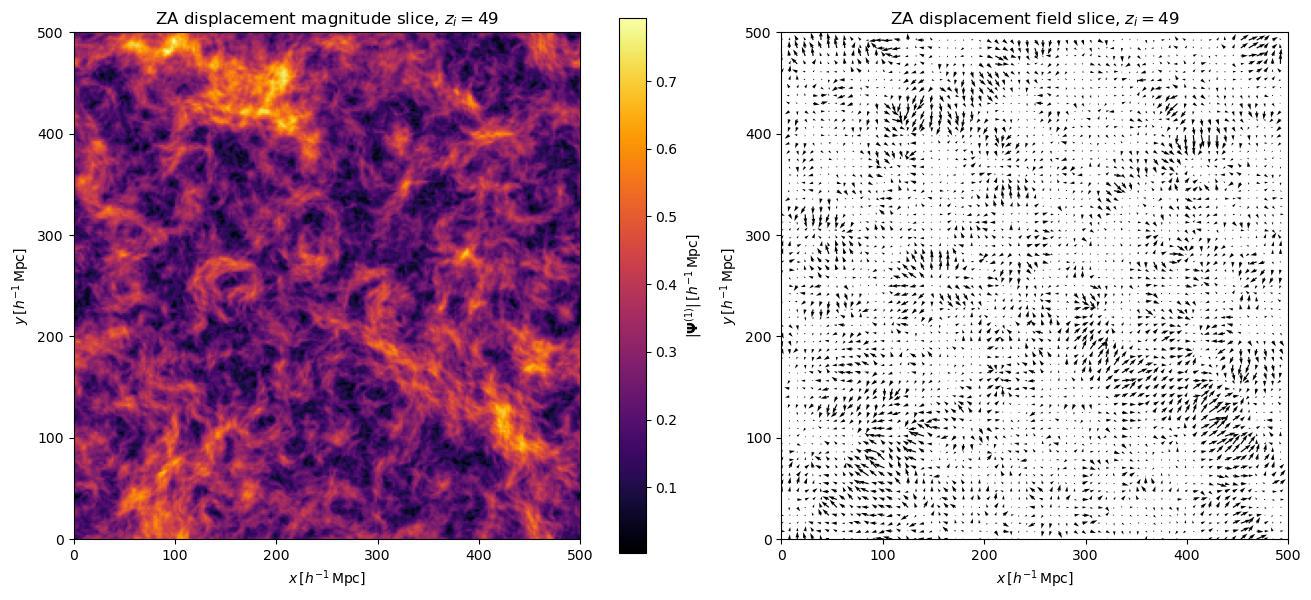

In [47]:
iz = N // 2
step = max(N // 64, 1)

xgrid = np.arange(N) * L / N
X, Y = np.meshgrid(xgrid[::step], xgrid[::step], indexing="ij")

fig, ax = plt.subplots(ncols=2, figsize=(13, 6), layout="constrained")

im = ax[0].imshow(psi_mag[:, :, iz].T, origin="lower", extent=(0, L, 0, L), aspect="equal", cmap="inferno")

ax[0].set_xlabel(r"$x\,[h^{-1}\,\mathrm{Mpc}]$")
ax[0].set_ylabel(r"$y\,[h^{-1}\,\mathrm{Mpc}]$")
ax[0].set_title(rf"ZA displacement magnitude slice, $z_i={z_i:.0f}$")

ax[1].quiver(X, Y, psi_x[0, ::step, ::step, iz], psi_x[1, ::step, ::step, iz], angles="xy")

ax[1].set_xlim(0, L)
ax[1].set_ylim(0, L)
ax[1].set_aspect("equal")

ax[1].set_xlabel(r"$x\,[h^{-1}\,\mathrm{Mpc}]$")
ax[1].set_ylabel(r"$y\,[h^{-1}\,\mathrm{Mpc}]$")
ax[1].set_title(rf"ZA displacement field slice, $z_i={z_i:.0f}$")

fig.colorbar(im, ax=ax[0], label=r"$|\mathbf{\Psi}^{(1)}|\,[h^{-1}\,\mathrm{Mpc}]$")
plt.savefig("../outputs/figures/03_ZA_displacement.png", dpi=200)
plt.show()

The previous Figure presents the resulting displacement field magnitude at a $z-\mathrm{axis}$ slice, and the corresponding vectorial map of the in-plane $x,y$ components of such field.

In [44]:
q = lpt.uniformLattice(N, L)
psi_p = np.moveaxis(psi_x, 0, -1)
x_p, v_p = lpt.zaParticles(q, psi_p, L, Hconf_i, f_i)

print("q shape   =", q.shape)
print("x_p shape =", x_p.shape)
print("v_p shape =", v_p.shape)

q shape   = (256, 256, 256, 3)
x_p shape = (256, 256, 256, 3)
v_p shape = (256, 256, 256, 3)


In [45]:
speed = np.linalg.norm(v_p, axis=-1)

print(f"x minimum = {x_p.min():.6f} Mpc/h")
print(f"x maximum = {x_p.max():.6f} Mpc/h")

print()
print(f"RMS speed = {np.sqrt(np.mean(speed**2)):.3f} km/s")
print(f"max speed = {speed.max():.3f} km/s")

x minimum = 0.000001 Mpc/h
x maximum = 499.999998 Mpc/h

RMS speed = 80.677 km/s
max speed = 266.210 km/s


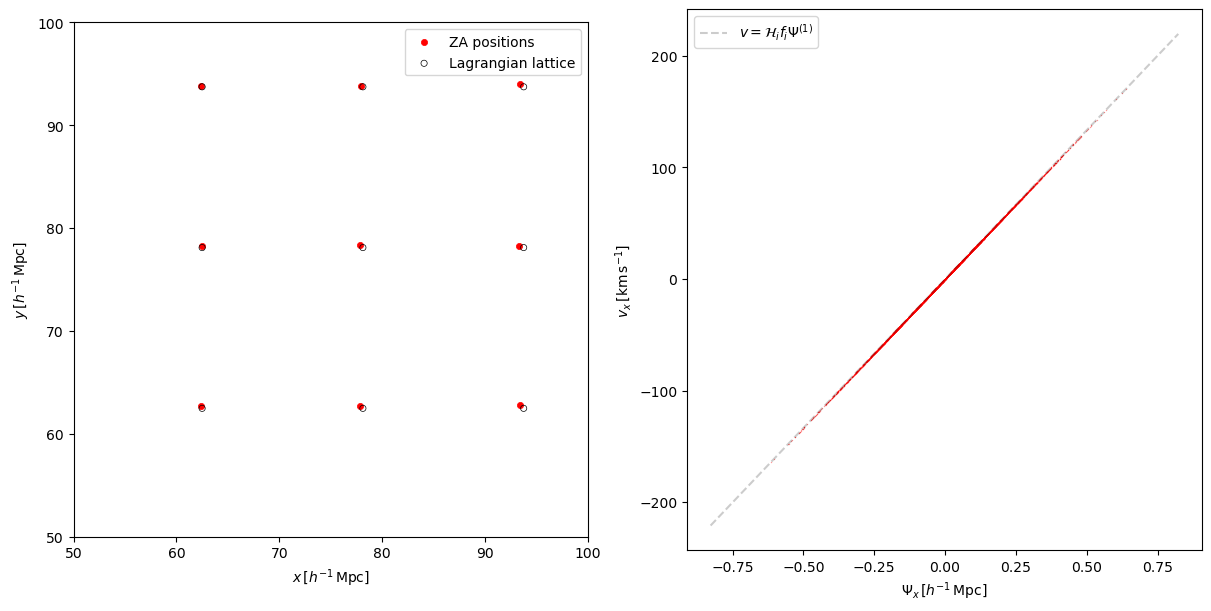

In [46]:
iz = N // 2
step = max(N // 32, 1)

q_slice = q[::step, ::step, iz]
x_slice = x_p[::step, ::step, iz]

psi_flat = psi_p[..., 0].ravel()
v_flat = v_p[..., 0].ravel()

sample = np.linspace(0, psi_flat.size - 1, min(5000, psi_flat.size), dtype=int)
xx = np.linspace(psi_flat.min(), psi_flat.max(), 200)


fig, ax = plt.subplots(ncols=2, figsize=(12, 6), layout="constrained")

ax[0].scatter(x_slice[..., 0].ravel(), x_slice[..., 1].ravel(), s=20, lw=0.5, facecolors="r", label="ZA positions")
ax[0].scatter(q_slice[..., 0].ravel(), q_slice[..., 1].ravel(), s=20, lw=0.5, facecolors='none', edgecolors='k', label="Lagrangian lattice")

ax[0].set_xlim(50, 100)
ax[0].set_ylim(50, 100)
ax[0].set_aspect("equal")

ax[0].set_xlabel(r"$x\,[h^{-1}\,\mathrm{Mpc}]$")
ax[0].set_ylabel(r"$y\,[h^{-1}\,\mathrm{Mpc}]$")
ax[0].legend()

ax[1].scatter(psi_flat[sample], v_flat[sample], s=1, alpha=0.4, lw=0, facecolors="r")
ax[1].plot(xx, Hconf_i * f_i * xx, ls="--", alpha=0.2, c="k", label=r"$v=\mathcal{H}_i f_i\Psi^{(1)}$")

ax[1].set_xlabel(r"$\Psi_x\,[h^{-1}\,\mathrm{Mpc}]$")
ax[1].set_ylabel(r"$v_x\,[\mathrm{km\,s^{-1}}]$")
ax[1].legend()

plt.savefig("../outputs/figures/03_lattice.png", dpi=200)
plt.show()

At last, in the left panel we show a slice of the small deviations for particles sampled over a 3D Lagragian lattice (open black circles) and their ZA perturbed positions (filled red circles). In the right panel, we also show that their velocities are sampled directly from the expected $\mathbf{v}=\mathcal{H}_if_i\Psi^{(1)}$.

# Validations (3c)

In [21]:
# --- Gaussian-field checks ---
delta_k_roundtrip = dx**3 * np.fft.rfftn(delta_x)
roundtrip_residual = np.linalg.norm(delta_k_roundtrip - delta_k) / np.linalg.norm(delta_k)
delta_full = dx**3 * np.fft.fftn(delta_x)

idx = (-np.arange(N)) % N
delta_minus = delta_full[np.ix_(idx, idx, idx)]

hermitian_residual = np.linalg.norm(delta_minus - np.conj(delta_full)) / np.linalg.norm(delta_full)

delta_complex = np.fft.ifftn(delta_full / dx**3)
imag_residual = np.max(np.abs(delta_complex.imag))

print("Gaussian field")
print("----------------------------")
print(f"<delta>                = {delta_x.mean():.3e}")
print(f"zero mode              = {delta_k[0,0,0]}")
print(f"Hermitian residual     = {hermitian_residual:.3e}")
print(f"FFT round-trip residual= {roundtrip_residual:.3e}")
print(f"max imaginary residual = {imag_residual:.3e}")

Gaussian field
----------------------------
<delta>                = 2.412e-18
zero mode              = 0j
Hermitian residual     = 4.416e-16
FFT round-trip residual= 4.593e-16
max imaginary residual = 4.754e-15


As expected from before, we confirm the zero average, zero mode and negligible residuals from FFT and Hermitian symmetry.

In [22]:
# --- ZA displacement checks ---
minus_div_k = -1j * (kx * psi_k[0] + ky * psi_k[1] + kz * psi_k[2])

target_k = D_i * delta_used

div_residual = np.linalg.norm(minus_div_k - target_k) / np.linalg.norm(target_k)

curl_x_k = 1j * (ky * psi_k[2] - kz * psi_k[1])
curl_y_k = 1j * (kz * psi_k[0] - kx * psi_k[2])
curl_z_k = 1j * (kx * psi_k[1] - ky * psi_k[0])

curl_norm = np.sqrt(np.linalg.norm(curl_x_k)**2 + np.linalg.norm(curl_y_k)**2 + np.linalg.norm(curl_z_k)**2)
curl_residual = curl_norm / np.linalg.norm(target_k)

psi_mean = psi_x.mean(axis=(1, 2, 3))

print("\nZA displacement")
print("----------------------------")
print(f"divergence residual     = {div_residual:.3e}")
print(f"curl residual           = {curl_residual:.3e}")
print(f"<Psi> [Mpc/h]           = ({psi_mean[0]:.3e}, {psi_mean[1]: .3e}, {psi_mean[2]: .3e})")

minus_div_x = np.fft.irfftn(minus_div_k / dx**3, s=(N, N, N), axes=(0, 1, 2))
target_x = np.fft.irfftn(target_k / dx**3, s=(N, N, N), axes=(0, 1, 2))
real_div_residual = np.linalg.norm(minus_div_x - target_x) / np.linalg.norm(target_x)

print(f"real-space div residual = {real_div_residual:.3e}")


ZA displacement
----------------------------
divergence residual     = 1.360e-16
curl residual           = 5.754e-17
<Psi> [Mpc/h]           = (5.164e-17, -1.999e-19, -2.917e-21)
real-space div residual = 4.143e-16


We also show that the $\Psi$ field has negligible curl, zero average, and the expected divergence $-\nabla\cdot\mathbf{\Psi}^{(1)}=D_1\sigma_\mathrm{ref}$.

In [23]:
# --- Particle checks ---
inside_box = np.all(x_p >= 0.0) and np.all(x_p < L)
Np_total = N**3

# unit masses
masses = np.ones(Np_total)
M_initial = masses.sum()
M_final = masses.sum()

mean_displacement = psi_p.reshape(-1, 3).mean(axis=0)
mean_velocity = v_p.reshape(-1, 3).mean(axis=0)

print("\nParticles")
print("----------------------------")
print(f"positions in [0,L)     = {inside_box}")
print(f"N particles            = {Np_total}")
print(f"total mass initial     = {M_initial:.0f}")
print(f"total mass final       = {M_final:.0f}")
print(
    "mean displacement      = "
    f"({mean_displacement[0]: .3e}, "
    f"{mean_displacement[1]: .3e}, "
    f"{mean_displacement[2]: .3e}) Mpc/h"
)
print(
    "mean velocity          = "
    f"({mean_velocity[0]: .3e}, "
    f"{mean_velocity[1]: .3e}, "
    f"{mean_velocity[2]: .3e}) km/s"
)


Particles
----------------------------
positions in [0,L)     = True
N particles            = 16777216
total mass initial     = 16777216
total mass final       = 16777216
mean displacement      = ( 5.164e-17, -1.999e-19, -2.917e-21) Mpc/h
mean velocity          = ( 3.554e-15,  5.204e-18,  7.991e-19) km/s


All perturbed particles lie within the expected $[0,L)$ periodic box, the total mass is preserved, and the displacement and velocity provided have a global zero mean, preserving isotropy.

In [24]:
# --- Velocity normalization ---
v_expected = Hconf_i * f_i * psi_p
velocity_residual = np.linalg.norm(v_p - v_expected) / np.linalg.norm(v_expected)

print("\nVelocity normalization")
print("----------------------------")
print(f"relative residual       = {velocity_residual:.3e}")


Velocity normalization
----------------------------
relative residual       = 0.000e+00


As a compliment the previous Figure, the perturbed velocity of each particle is indeed the expected ZA calculation.

# Spectrum comparision (3d)

In [6]:
seeds = np.arange(16)
ens64 = lpt.runZaEnsemble(64, L, seeds, D_i, classPower)
ens128 = lpt.runZaEnsemble(128, L, seeds, D_i, classPower)
ens256 = lpt.runZaEnsemble(256, L, seeds, D_i, classPower)

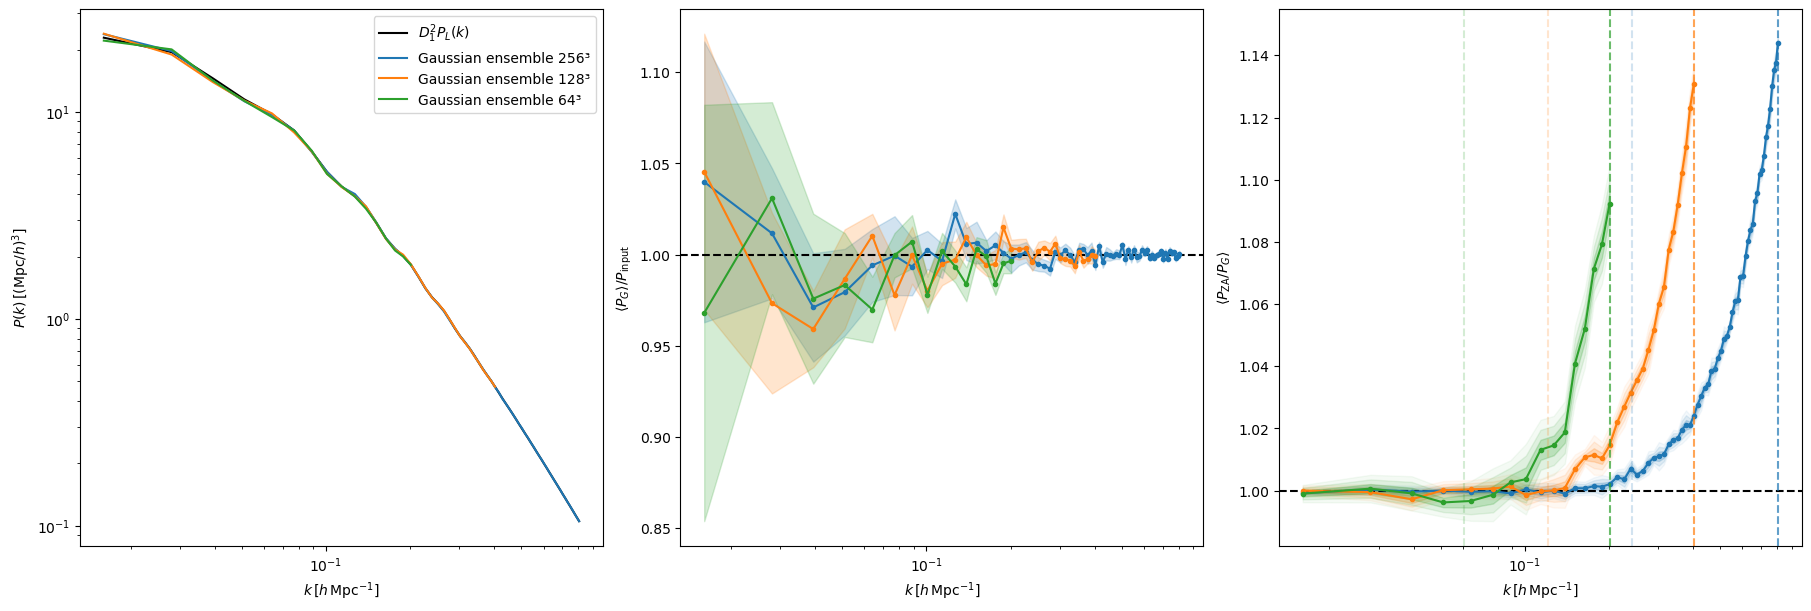

P_ZA error under 0.3k_Ny (N³=256³) =  0.0013801272769133257
P_ZA error under 0.3k_Ny (N³=128³) =  0.0008370453961445238
P_ZA error under 0.3k_Ny (N³=64³)  =  0.0015575572660821435


In [13]:
stats256 = lpt.ensembleStatistics(ens256)
k256 = ens256["k"]
Pinput256 = ens256["Pinput"]
Rg256 = stats256["Pg_mean"] / Pinput256
Rg_sem256 = stats256["Pg_sem"] / Pinput256
pmean256 = stats256["paired_mean"]
psem256 = stats256["paired_sem"]

stats128 = lpt.ensembleStatistics(ens128)
k128 = ens128["k"]
Pinput128 = ens128["Pinput"]
Rg128 = stats128["Pg_mean"] / Pinput128
Rg_sem128 = stats128["Pg_sem"] / Pinput128
pmean128 = stats128["paired_mean"]
psem128 = stats128["paired_sem"]

stats64 = lpt.ensembleStatistics(ens64)
k64 = ens64["k"]
Pinput64 = ens64["Pinput"]
Rg64 = stats64["Pg_mean"] / Pinput64
Rg_sem64 = stats64["Pg_sem"] / Pinput64
pmean64 = stats64["paired_mean"]
psem64 = stats64["paired_sem"]

fig, ax = plt.subplots(ncols=3, figsize=(18, 6), sharex=True, layout="constrained")

ax[0].loglog(k256, Pinput256, "k-", label=r"$D_1^2 P_L(k)$")
ax[0].loglog(k256, stats256["Pg_mean"], label="Gaussian ensemble 256³")
ax[0].loglog(k128, stats128["Pg_mean"], label="Gaussian ensemble 128³")
ax[0].loglog(k64,  stats64["Pg_mean"],  label="Gaussian ensemble 64³")

ax[0].set_xlabel(r"$k\,[h\,\mathrm{Mpc}^{-1}]$")
ax[0].set_ylabel(r"$P(k)\,[(\mathrm{Mpc}/h)^3]$")
ax[0].legend()

ax[1].axhline(1.0, ls="--", c="k")
ax[1].plot(k256, Rg256, marker="o", ms=3)
ax[1].plot(k128, Rg128, marker="o", ms=3)
ax[1].plot(k64,  Rg64,  marker="o", ms=3)

ax[1].fill_between(k256, Rg256 -   Rg_sem256, Rg256 +   Rg_sem256, alpha=0.2,  color="C0")
ax[1].fill_between(k128, Rg128 -   Rg_sem128, Rg128 +   Rg_sem128, alpha=0.2,  color="C1")
ax[1].fill_between(k64, Rg64 -   Rg_sem64, Rg64 +   Rg_sem64, alpha=0.2,  color="C2")

ax[1].set_xscale("log")
ax[1].set_ylabel(r"$\langle P_G\rangle/P_{\rm input}$")
ax[1].set_xlabel(r"$k\,[h\,\mathrm{Mpc}^{-1}]$")

# Paired ZA/Gaussian comparison
ax[2].axhline(1.0, ls="--", c="k")
ax[2].plot(k256, pmean256, marker="o", ms=3)
ax[2].plot(k128, pmean128, marker="o", ms=3)
ax[2].plot(k64,  pmean64,  marker="o", ms=3)

ax[2].fill_between(k256, pmean256 -   psem256, pmean256 +   psem256, alpha=0.2,  color="C0")
ax[2].fill_between(k256, pmean256 - 2*psem256, pmean256 + 2*psem256, alpha=0.1,  color="C0")
ax[2].fill_between(k256, pmean256 - 3*psem256, pmean256 + 3*psem256, alpha=0.05, color="C0")

ax[2].fill_between(k128, pmean128 -   psem128, pmean128 +   psem128, alpha=0.2,  color="C1")
ax[2].fill_between(k128, pmean128 - 2*psem128, pmean128 + 2*psem128, alpha=0.1,  color="C1")
ax[2].fill_between(k128, pmean128 - 3*psem128, pmean128 + 3*psem128, alpha=0.05, color="C1")

ax[2].fill_between(k64, pmean64 -   psem64, pmean64 +   psem64, alpha=0.2,  color="C2")
ax[2].fill_between(k64, pmean64 - 2*psem64, pmean64 + 2*psem64, alpha=0.1,  color="C2")
ax[2].fill_between(k64, pmean64 - 3*psem64, pmean64 + 3*psem64, alpha=0.05, color="C2")

ax[2].axvline(k256[-1], c="C0", ls="--", alpha=0.7)
ax[2].axvline(k128[-1], c="C1", ls="--", alpha=0.7)
ax[2].axvline(k64[-1],  c="C2", ls="--", alpha=0.7)

ax[2].axvline(0.3*k256[-1], c="C0", ls="--", alpha=0.2)
ax[2].axvline(0.3*k128[-1], c="C1", ls="--", alpha=0.2)
ax[2].axvline(0.3*k64[-1],  c="C2", ls="--", alpha=0.2)

ax[2].set_xscale("log")
ax[2].set_ylabel(r"$\langle P_{\rm ZA}/P_G\rangle$")
ax[2].set_xlabel(r"$k\,[h\,\mathrm{Mpc}^{-1}]$")

plt.savefig("../outputs/figures/03_spectrum.png", dpi=200)
plt.show()

mask256 = k256 < 0.3*k256[-1]
mask128 = k128 < 0.3*k128[-1]
mask64  = k64  < 0.3*k64[-1]

print("P_ZA error under 0.3k_Ny (N³=256³) = ", np.average(np.abs(pmean256[mask256]-1)))
print("P_ZA error under 0.3k_Ny (N³=128³) = ", np.average(np.abs(pmean128[mask128]-1)))
print("P_ZA error under 0.3k_Ny (N³=64³)  = ", np.average(np.abs(pmean64[mask64]-1)))

Here, we compare the power spectra over an ensamble of 16 realizations for each resolution $(64^3,128^3,256^3)$, as to mitigate numerical deviations.

In the first panel, we compare the spectra of the gaussian fields of each resolution with the input power spectra. In the second panel, it is shown the residuals from $\langle P_G(k)\rangle / P_\mathrm{input}$ comparing the input spectra with the realizations. The first points have a bigger scatter, since they include less modes sampled. However, we can see that the entire $k$ spectra is in agreement with the expected input, with $\langle P_G(k)\rangle / P_\mathrm{input}\simeq1$.

The behaviour is different, however, when we compare with the spectra of the ZA sampled particles. Since we use a Cloud-In-Cell (CIC) method to infer the power spectra of these particles, we must apply a window
\begin{equation}
W_\mathrm{CIC}(\mathbf{k})=\prod_{i=x,y,z}\left[\frac{\sin(k_i\delta x/2)}{k_i\Delta x/2}\right]^2.
\end{equation}

At big scales (i.e. low values of $k$) the spectra of the particles agree with the input power spectra. As we approach the Nyquist frequency (dotted vertical lines in the third panel), we can see that the measured spectra is systematically higher than the input. Since for a resolution of $N^3$ 3D particles the Nyquist frequency grows with $\propto N$, how ``safe'' the particle power spectra is for a given $k$ gets better as we increase the spatial resolution. From the graph, we can see that already at $k<0.5k_\mathrm{Ny}$ reach a relative deviation no bigger than $4\%$ for this experiment. At even more conservative Nyquist cuts, we get $\langle\lvert P_\mathrm{ZA}/P_\mathrm{G}-1\rvert\rangle\lesssim1.6\times10^{-3}$ at $k<0.3 k_\mathrm{Ny}$ (low opacity vertical lines).

Therefore the gaussian generator reproduces the linear spectra provided without detectable bias and satisfied the required Fourier conventions to machine precision. The ZA implementation also satisfies the desired curl, divergence, normalization and average conditions. After CIC deposit of particles, their spectra recovers the large-scale spectra if we also choose a sufficiently good interval of frequencies, such as under $0.3k_\mathrm{Ny}$, for quantitative comparisions.